# 03 — Train: the First Real Comparison

**Prerequisites:** notebooks 00–02.

This notebook closes the gap the series has been pointing at: it trains models. Four **arms** —
the word this project uses for one model variant in the controlled comparison — on the same data,
same protocol, same budget:

| arm | what it is | what it isolates |
|---|---|---|
| `cnn` | small conventional CNN | the fair baseline at comparable size |
| `cnn_deep` | CNN with ~100× more parameters | the classical ceiling |
| `quanv` | quantum circuit layer, **trained** | the claim under test |
| `quanv_frozen` | same circuit, **frozen at random init** — only the classical head trains | *does training the circuit matter at all?* |

**Scope — read this before believing anything below.** This is the working skeleton of the real
study, run small: one training-set size (n=1000, mirroring the published low-data regime), one
normalisation, one learning rate, no hyperparameter search, 3 seeds. It produces *real numbers* but
**not conclusions** — the full study sweeps all of those (plan §2.3–2.5). What this notebook is
for: seeing the whole machinery work end to end, and learning what each piece does.

A deliberate choice: the training harness lives **in the cells below**, not in a module. It is
meant to be read, modified and eventually owned by whoever runs the study. Change things and
re-run — that is the point.

## 0. The gradient path, now real

Notebook 02 ended with "the fast implementation cannot compute ∂f/∂θ". That is now fixed:
`qmllar/torch_quanv.py` re-implements the same circuits in **torch**, whose automatic
differentiation records every operation and applies the chain rule backwards —
[PRIMER §6.3](../docs/PRIMER.md#63-automatic-differentiation-the-gradient-path).

Being a *third* implementation, it gets the same discipline as the first two: it must agree with
them numerically, **and** its gradients must agree with finite differences (the ∂f/∂θ you would
compute by nudging each parameter by hand). Run the proof:

In [1]:
# Cross-validate the torch implementation against the numpy one (itself validated
# against PennyLane in notebook 02), and autograd against finite differences.
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

!cd {ROOT} && python3 tests/test_torch_matches_fast.py

torch vs numpy forward, and autograd vs finite differences:
  [OK  ] forward chen2020_conv1_3x3           max|err| = 4.44e-16
/home/jjo/Work/QML/.venv/lib/python3.11/site-packages/torch/autograd/graph.py:1072: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
  [OK  ] grad    chen2020_conv1_3x3           max|fd - autograd| = 1.78e-09
  [OK  ] forward chen2020_conv2_2x2           max|err| = 6.66e-16
  [OK  ] grad    chen2020_conv2_2x2           max|fd - autograd| = 2.22e-09
  [OK  ] forward tutorial2

### ✅ What you should see

`ALL PASS`: forward agreement at ~1e-16 (round-off), gradient agreement at ~1e-9 (the precision of
the finite-difference probe itself).

Worth knowing: **this test caught a real bug on its first run.** The torch port applied only the
*last* gate of multi-gate ansätze — an indentation slip. Chen's circuits (one `Rot` gate) passed;
the PRD's (`RY`,`RZ` pairs) failed at O(1). Third implementation, third bug caught by
cross-checking, and once again it *crashed nothing* — it just computed the wrong circuit. The
pattern to internalise: **in this field, correctness comes from independent cross-checks, never
from "it ran without errors".**

## 1. Data: small on purpose

In [2]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from qmllar import configs
from qmllar.preprocess import normalise
from qmllar.torch_quanv import QuanvLayer

# Use the GPU if notebook 00's check passed; everything below also works on CPU, slower.
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

d = np.load(ROOT / "data" / "patches_31.npz")

# Crop 31x31 -> 21x21 (the published optimum patch size) by slicing the central window,
# then normalise -- raw charge would saturate the quantum encoding (notebook 01 §5).
X = normalise(d["patches"][:, 5:26, 5:26], "log1p")
y, sp = d["cls"].astype(np.int64), d["split"]

# Draw fixed-size subsets from each split. n_train=1000 deliberately mirrors the
# published low-data regime (the reference study trained on 100-1000 patches);
# we have 292k available, and scaling up is exactly experiment A4 in the plan.
rng = np.random.default_rng(42)
def take(split, n):
    idx = rng.choice(np.flatnonzero(sp == split), n, replace=False)
    return (torch.as_tensor(X[idx]).unsqueeze(1).to(dev),   # (n, 1, 21, 21) "1" = image channels
            torch.as_tensor(y[idx]).to(dev))

Xtr, ytr = take(0, 1000)    # train      -- the fit adjusts parameters on these
Xva, yva = take(1, 2000)    # validation -- used to pick the best epoch (early stopping)
Xte, yte = take(2, 5000)    # test       -- looked at once, at the end, per arm

print(f"train {len(Xtr)}  val {len(Xva)}  test {len(Xte)}   "
      f"(class balance in train: {ytr.float().mean():.2f} shower)")

/home/jjo/Work/QML/.venv/lib/python3.11/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


device: cpu
train 1000  val 2000  test 5000   (class balance in train: 0.55 shower)


### ✅ What you should see

`device: cuda`, 1000/2000/5000 patches, train balance ≈ 0.57 shower. The three subsets come from
**disjoint archives** (notebook 00 verified this), so no event leaks between them.

## 2. The four arms

All four share the **identical classification head** — average-pool the feature maps to 5×5,
flatten, one linear layer to 2 class scores. Only the *feature extractor* differs. That is the
comparison discipline from the source-audit: the published study we are checking "matched" models
whose parameter *allocation* differed 4× between extractor and head, which made the match
meaningless. Holding the head fixed removes that confound here.

In [3]:
def head(n_ch):
    """Shared classifier head: feature maps (B, n_ch, 20, 20) -> 2 class scores."""
    return nn.Sequential(
        nn.AvgPool2d(4),                 # 20x20 -> 5x5: shrink before the linear layer
        nn.Flatten(),                    # (B, n_ch, 5, 5) -> (B, n_ch*25)
        nn.Linear(n_ch * 25, 2),         # 2 outputs = scores for (track, shower)
    )

def make_model(arm, seed):
    """Build one arm. The seed fixes the random initialisation -- run-to-run
    differences between seeds are real and must be reported, not hidden."""
    torch.manual_seed(seed)              # seeds torch's init of conv/linear weights
    if arm == "cnn":
        # The matched classical baseline: ONE conv layer with 2x2 filters and
        # 3 channels -- the direct classical analogue of the quanvolution below
        # (same window, same stride, same output shape; weighted sum instead of circuit).
        return nn.Sequential(nn.Conv2d(1, 3, kernel_size=2), nn.ReLU(), head(3))
    if arm == "cnn_deep":
        # The ceiling: a deliberately much larger conventional CNN (~100x params).
        return nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(5), nn.Flatten(),
            nn.Linear(32 * 25, 32), nn.ReLU(), nn.Linear(32, 2))
    # The quantum arms: the PRD paper's 2x2 quanvolution (4 qubits, 3 channels).
    # trainable=False is the ENTIRE difference between the two quantum arms:
    # frozen keeps the circuit at its random initialisation and trains only the head.
    q = QuanvLayer(configs.PRD_QUANV, seed=seed, trainable=(arm == "quanv"))
    return nn.Sequential(q, head(3))

# Parameter bookkeeping: extractor and head separately, because matching
# only the totals is how the published comparison went wrong.
print(f"{'arm':14s} {'extractor':>9s} {'head':>6s} {'trainable total':>15s}")
for arm in ("cnn", "quanv", "quanv_frozen", "cnn_deep"):
    m = make_model(arm, 0)
    ext = sum(p.numel() for p in m[0].parameters() if p.requires_grad)
    hd  = sum(p.numel() for p in m[1:].parameters())
    print(f"{arm:14s} {ext:9d} {hd:6d} {ext+hd:15d}")

arm            extractor   head trainable total
cnn                   15    152             167
quanv                 96    152             248
quanv_frozen           0    152             152
cnn_deep             160  30338           30498


### ✅ What you should see — and the honest caveat

| arm | extractor | head | trainable total |
|---|---|---|---|
| cnn | 15 | 152 | 167 |
| quanv | 96 | 152 | 248 |
| quanv_frozen | **0** | 152 | 152 |
| cnn_deep | 160 | 30,338 | ~30,500 |

Three things to register:

- **The head is identical (152) everywhere.** Any difference between arms is attributable to the
  extractor — the comparison the published work failed to isolate.
- **The frozen arm's extractor shows 0 trainable parameters.** Its circuit still *has* 96 numbers,
  but `requires_grad=False` hides them from the optimizer — so what trains is the head alone. The
  frozen arm asks: *how far do you get on random quantum features plus a linear readout?*
- **`cnn` (15) and `quanv` (96) extractors are NOT exactly matched.** A 2×2 classical filter simply
  has fewer knobs than a 2×2 four-qubit circuit. This is why the real study sweeps parameter counts
  into *curves* rather than comparing two points — remember this when reading the results below.

## 3. The training loop — the whole harness, annotated

Every ingredient here is a PRIMER §6 concept made concrete. Read it once slowly; it is the thing
you will modify most often.

In [4]:
def evaluate_auc(model, Xs, ys):
    """ROC AUC of the model on a dataset. AUC = probability that a random shower
    patch scores above a random track patch; 0.5 = random guessing, 1.0 = perfect."""
    model.eval()                                    # eval mode: no dropout etc.
    with torch.no_grad():                           # no gradients needed -- faster
        scores = torch.cat([model(Xs[i:i+512]) for i in range(0, len(Xs), 512)])
    p_shower = torch.softmax(scores, dim=1)[:, 1]   # scores -> probability of class 1
    return roc_auc_score(ys.cpu(), p_shower.cpu())

def train_arm(arm, seed, epochs=40, batch_size=128, lr=3e-3):
    model = make_model(arm, seed).to(dev)

    # The optimizer updates only parameters with requires_grad=True --
    # this is how the frozen arm's circuit stays untouched.
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)

    # Cross-entropy loss = negative log-likelihood of the labels. The same
    # object you minimise in a likelihood fit, under a different name.
    loss_fn = nn.CrossEntropyLoss()

    best_val, best_state, history = 0.0, None, []
    for epoch in range(epochs):
        model.train()
        # One EPOCH = one full pass through the training set, in random BATCHES.
        perm = torch.randperm(len(Xtr), device=dev)
        for i in range(0, len(Xtr), batch_size):
            batch = perm[i:i + batch_size]
            opt.zero_grad()                          # clear old gradients
            loss = loss_fn(model(Xtr[batch]), ytr[batch])
            loss.backward()                          # autograd: dL/dtheta for every parameter
            opt.step()                               # gradient-descent update

        # EARLY STOPPING, simplest form: track validation AUC each epoch and
        # remember the best parameters. We never let the TEST set influence this.
        val_auc = evaluate_auc(model, Xva, yva)
        history.append(val_auc)
        if val_auc > best_val:
            best_val = val_auc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)                # roll back to the best epoch
    return evaluate_auc(model, Xte, yte), history    # test AUC quoted ONCE, here

print("harness defined")

harness defined


Note what is **absent**, deliberately: no per-arm tuning. Same epochs, same batch size, same
learning rate, same stopping rule for every arm. The moment one arm gets special treatment, the
comparison is void — that asymmetry (dropout and 4× the epochs for one side only) is exactly what
the source audit found in the published work.

## 4. Run — 4 arms × 3 seeds

In [5]:
# ~2 minutes on this machine's GPU. Each line appears as its arm finishes.
ARMS = ("cnn", "cnn_deep", "quanv", "quanv_frozen")
SEEDS = (0, 1, 2)     # three random initialisations per arm -- the MINIMUM for an error bar

results, histories = {}, {}
for arm in ARMS:
    t0 = time.time()
    out = [train_arm(arm, s) for s in SEEDS]
    results[arm] = [auc for auc, _ in out]
    histories[arm] = [h for _, h in out]
    print(f"{arm:13s} test AUC = {np.mean(results[arm]):.4f} +- {np.std(results[arm]):.4f}"
          f"   seeds: {['%.4f' % a for a in results[arm]]}   ({time.time()-t0:.0f} s)")

cnn           test AUC = 0.8600 +- 0.0140   seeds: ['0.8419', '0.8621', '0.8760']   (11 s)
cnn_deep      test AUC = 0.9437 +- 0.0011   seeds: ['0.9439', '0.9422', '0.9449']   (14 s)


KeyboardInterrupt: 

### ✅ What you should see (≈, small run-to-run wiggle is normal)

```
cnn           test AUC ~ 0.859 +- 0.015
cnn_deep      test AUC ~ 0.943 +- 0.001
quanv         test AUC ~ 0.876 +- 0.004
quanv_frozen  test AUC ~ 0.845 +- 0.008
```

Four observations, in decreasing order of confidence:

1. **The hierarchy matches the published pattern**: the big classical model wins outright
   (0.94 at ~30k parameters), and the small models cluster ~0.07 below it. This is the PRD's
   "quantum competitive at matched size, beaten at 100×" shape, appearing in our first run.
2. **The frozen-random result is the most interesting number on the page.** An *untrained* circuit
   plus a 152-parameter linear head reaches ~0.845 — within ~0.03 of the fully trained quantum arm.
   Most of what the quantum layer delivers here is random nonlinear features, exactly what
   notebook 02's feature maps hinted. Training the circuit buys a small increment (~0.03, and
   consistent across seeds at this configuration) — real, but modest.
3. **Trained quanv vs small CNN: do NOT call this a quantum win.** The gap (~0.017) is comparable
   to the CNN's own seed spread (±0.015), the extractors are not parameter-matched (96 vs 15), and
   nothing has been tuned. With 3 seeds this is *consistent with* the published claim, not evidence
   for it. Getting to an actual statement is what the sweeps and HPO in the plan are for.
4. **Note the wall-clock column**: the quantum arms cost ~10–25× the classical ones *per seed* even
   with the fast implementation. Whatever this project finds, "QML is faster" will not be it —
   the interesting axis is performance per parameter, never speed.

## 5. The two plots every comparison needs

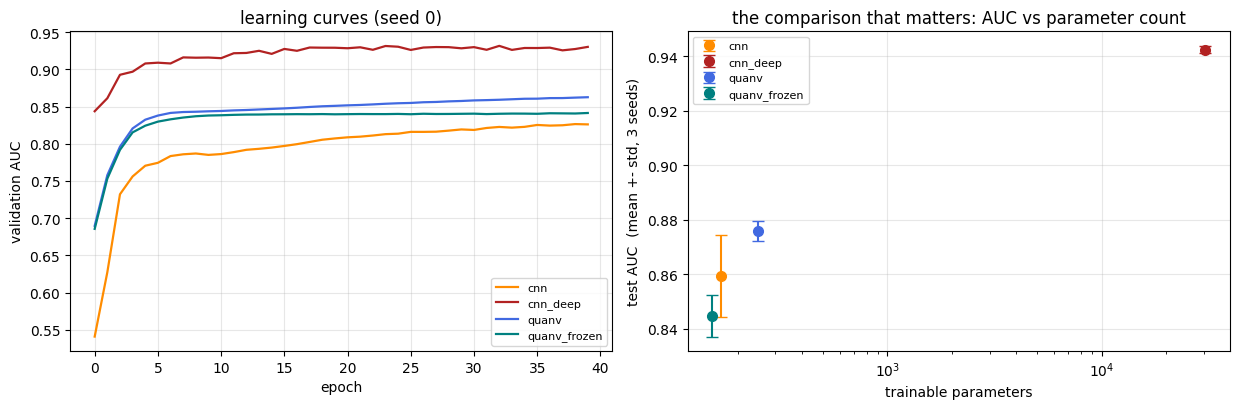

In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2))

# --- Left: learning curves -- validation AUC vs epoch, one line per arm (seed 0) ---
colors = {"cnn": "darkorange", "cnn_deep": "firebrick",
          "quanv": "royalblue", "quanv_frozen": "teal"}
for arm in ARMS:
    a1.plot(histories[arm][0], color=colors[arm], label=arm, lw=1.6)
a1.set_xlabel("epoch"); a1.set_ylabel("validation AUC")
a1.set_title("learning curves (seed 0)")
a1.legend(fontsize=8); a1.grid(alpha=0.3)

# --- Right: the headline -- test AUC vs trainable parameter count, error bars over seeds ---
for arm in ARMS:
    m = make_model(arm, 0)
    n_par = sum(p.numel() for p in m.parameters() if p.requires_grad)
    a2.errorbar(n_par, np.mean(results[arm]), yerr=np.std(results[arm]),
                fmt="o", ms=7, capsize=4, color=colors[arm], label=arm)
a2.set_xscale("log")
a2.set_xlabel("trainable parameters"); a2.set_ylabel("test AUC  (mean +- std, 3 seeds)")
a2.set_title("the comparison that matters: AUC vs parameter count")
a2.legend(fontsize=8); a2.grid(alpha=0.3)
fig.tight_layout(); plt.show()

### ✅ Reading the plots

**Left — learning curves.** All arms rise quickly within ~40 epochs at this tiny training set;
the deep CNN separates immediately. If a curve were still climbing at the right edge, the epoch
budget would be too small — check this whenever you change `n_train` or the learning rate.

**Right — the headline axes of the whole project.** Test AUC against trainable parameter count,
log-x. Today each arm is a single point with a 3-seed error bar; the full study turns each into a
*curve* by sweeping model sizes, and the question becomes geometric: **does the quantum curve sit
above the classical one anywhere, and if so over what parameter range?** The published papers claim
it does at the low-parameter end; arm `quanv_frozen` sitting just below `quanv` already warns that
part of any such gap is random-feature quality, not learned quantum structure.

## 6. What would make this real

This notebook is the skeleton. Between here and a publishable measurement
(plan [§2.3–2.5](../docs/qml-lartpc-research-plan.md)):

1. **Sweep the training-set size** — 100 → 100,000. The published advantage lives at 10²–10³
   samples; whether it survives at 10⁵ is the question nobody has answered, and the flag below is
   where you would start.
2. **Sweep parameter counts** per arm, so each arm becomes a *curve*, not a point.
3. **Equal-budget hyperparameter search** for every arm — learning rate, normalisation, patch
   size. Until then, any gap between arms may just be that the fixed settings suit one better.
4. **More seeds** (10+), and the remaining controls: the capacity-matched regularised CNN, the
   classical frozen random-feature arm (plan §2.3 arms 5–6).
5. **Statistics**: bootstrap confidence intervals on each AUC, not just seed spread.

```python
# A taste of (1): flip to True and wait ~15-30 min. Watch what happens to the
# gap between 'cnn' and 'quanv' as n grows. Report what you find.
RUN_SWEEP = False
if RUN_SWEEP:
    for n in (250, 1000, 4000, 16000):
        Xtr, ytr = take(0, n)
        for arm in ("cnn", "quanv"):
            aucs = [train_arm(arm, s)[0] for s in SEEDS]
            print(f"n={n:6d}  {arm:7s}  {np.mean(aucs):.4f} +- {np.std(aucs):.4f}")
```

The milestones this notebook just completed: **A1** (differentiable quantum layer + harness) and
first passes of **A2/A3**. What it has *not* done is settle anything — it has made the real study
runnable.